# Session 5b — Choosing fixed effects

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to the last block of lecture AE1.3 (Fixed Effects and Standard
Errors): from one-way to interacted fixed effects, and how to decide which
sets to include. Everything is simulated, so the truth is known and every
choice can be judged against it.

1. The saturation ladder: pooled → firm → firm + year → firm + region×year.
   Which confounder each set removes, and how much variation in the regressor
   survives.
2. The cost side: measurement error is *not* absorbed, so attenuation grows
   with every FE set — and if the extra set removes no confounder, it only
   hurts.
3. Fixed effects at the level of the treatment: when region×year FE absorb a
   regional program completely, and when they almost do.
4. Singletons: observations alone in their cell carry no information and drop
   out silently.
5. A banking example: Khwaja–Mian firm fixed effects vs. industry–location–
   size–time cells (Degryse et al. 2019) — demand absorbed better vs. more
   firms kept.

Readings: Breuer and deHaan (2024); Millimet and Bellemare (2025); Khwaja and
Mian (2008); Degryse, De Jonghe, Jakovljević, Mulier and Schepens (2019).
Full references at the end of the notebook.

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

rng = np.random.default_rng(20261116)
pd.set_option("display.precision", 4)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.family": "sans-serif"})


def demean(df, cols, fe=(), tol=1e-10, max_iter=500):
    # Project out several sets of fixed effects by iterated demeaning (alternating projections):
    # subtract group means for each FE set in turn until nothing moves. One set: ordinary within
    # transformation. This is what fixest / reghdfe / linearmodels do; dummies would be exactly
    # collinear here (region dummies are implied by firm dummies) and much slower.
    out = df[list(cols)].astype(float).copy()
    for _ in range(max_iter):
        before = out.to_numpy().copy()
        for f in fe:
            out = out - out.groupby(df[f]).transform("mean")
        if np.abs(out.to_numpy() - before).max() < tol:
            return out
    raise RuntimeError(f"demeaning did not converge in {max_iter} iterations")


def fe_fit(df, y, x, fe=(), cluster="i"):
    # OLS on demeaned variables; SEs clustered on `cluster`. Small-sample conventions for clustered SEs
    # after absorbed FE differ across packages (how absorbed parameters and singletons enter the
    # G/(G-1) * (N-1)/(N-K) factor); statsmodels' default is used as is, which is fine for the
    # comparisons here but not identical to reghdfe/fixest to the last digit.
    dd = demean(df, [y, x], fe) if fe else df[[y, x]].astype(float)
    X = sm.add_constant(dd[x].to_numpy()) if not fe else dd[[x]].to_numpy()
    if np.var(X[:, -1]) < 1e-12:
        return None                                                   # x fully absorbed by the FE: not identified
    fit = sm.OLS(dd[y].to_numpy(), X).fit(cov_type="cluster", cov_kwds={"groups": df[cluster].to_numpy()})
    return fit


def within_share(df, x, fe=()):
    # Share of Var(x) that survives the fixed effects.
    if not fe:
        return 1.0
    return demean(df, [x], fe)[x].var() / df[x].var()


def ladder(df, y, x, specs, cluster="i", truth=None):
    rows = []
    for name, fe in specs.items():
        f = fe_fit(df, y, x, fe, cluster)
        coef, se = (np.nan, np.nan) if f is None else (f.params[-1], f.bse[-1])
        rows.append({"coefficient": coef, "SE": se, "share of Var(d) left": within_share(df, x, fe), "N": len(df)})
    out = pd.DataFrame(rows, index=list(specs))
    if truth is not None:
        out.insert(1, "bias", out["coefficient"] - truth)
    return out


def plot_ladder(tab, truth=1.0, title=""):
    fig, ax1 = plt.subplots(figsize=(8, 3.6))
    xs = np.arange(len(tab))
    ax1.errorbar(xs, tab["coefficient"], yerr=1.96 * tab["SE"], fmt="o", color=VERMILLION, capsize=4, lw=1.5, label="coefficient ± 1.96 SE")
    ax1.axhline(truth, color=GREY, ls="--", lw=1, label=f"truth = {truth}")
    ax1.set_xticks(xs); ax1.set_xticklabels(tab.index, rotation=0); ax1.set_ylabel("coefficient on d")
    ax2 = ax1.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
    ax2.bar(xs, tab["share of Var(d) left"], width=0.35, alpha=0.25, color=BLUE, label="share of Var(d) left")
    ax2.set_ylim(0, 1.05); ax2.set_ylabel("share of Var(d) left", color=BLUE)
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right", fontsize=8); ax1.set_title(title)
    plt.tight_layout(); plt.show()

## 1. The saturation ladder

Firms $i$ in regions $r(i)$ ($R = 20$ regions, 30 firms each) observed for
$T = 10$ years. Outcome: investment $y_{it}$; regressor: bank credit $d_{it}$;
true effect $\delta = 1$. Two unobservables confound the regression, and they
live at different levels:

$$y_{it} = \alpha_i + \gamma_{r(i)t} + \delta\, d_{it} + \varepsilon_{it}, \qquad
  d_{it} = 0.6\,\alpha_i + 0.6\,\gamma_{r(i)t} + \nu_{it}.$$

$\alpha_i$ is firm quality (good firms get more credit and invest more);
$\gamma_{rt}$ is local demand (a regional boom raises both credit and
investment). Firm FE remove the first, year FE remove nothing here (there is
no national component in $\gamma_{rt}$), region×year FE remove the second.

In [2]:
def make_firm_panel(R=20, F=30, T=10, delta=1.0, load_alpha=0.6, load_gamma=0.6, gamma_in_y=1.0, rng=rng):
    N = R * F
    firm = np.repeat(np.arange(N), T); t = np.tile(np.arange(T), N); region = firm // F
    alpha = rng.normal(0, 1, N)
    gamma = rng.normal(0, 1, (R, T))
    nu = rng.normal(0, 1, N * T); eps = rng.normal(0, 1, N * T)
    d = load_alpha * alpha[firm] + load_gamma * gamma[region, t] + nu
    y = alpha[firm] + gamma_in_y * gamma[region, t] + delta * d + eps
    df = pd.DataFrame({"i": firm, "t": t, "r": region, "d": d, "y": y})
    df["rt"] = df["r"].astype(str) + "-" + df["t"].astype(str)        # region-year cell
    df["alpha"] = alpha[firm]; df["gamma_rt"] = gamma[region, t]      # kept only to check the DGP
    return df

df = make_firm_panel()
SPECS = {"pooled": (), "firm": ("i",), "firm + year": ("i", "t"), "firm + region×year": ("i", "rt")}
tab1 = ladder(df, "y", "d", SPECS, truth=1.0)
tab1

,coefficient,bias,SE,share of Var(d) left,N
pooled,1.6980,0.6980,0.0185,1.0000,6000
firm,1.4388,0.4388,0.0146,0.7061,6000
firm + year,1.4155,0.4155,0.0149,0.6904,6000
firm + region×year,0.9901,-0.0099,0.0139,0.4991,6000


Each FE set removes the confounder that lives at its level, and the bias
shrinks step by step. Note the last column: region×year FE leave only part of
the variation in $d$ for identification — the within-firm, within-region-year
part. That is the clean part here, by construction, so the SE is still fine.

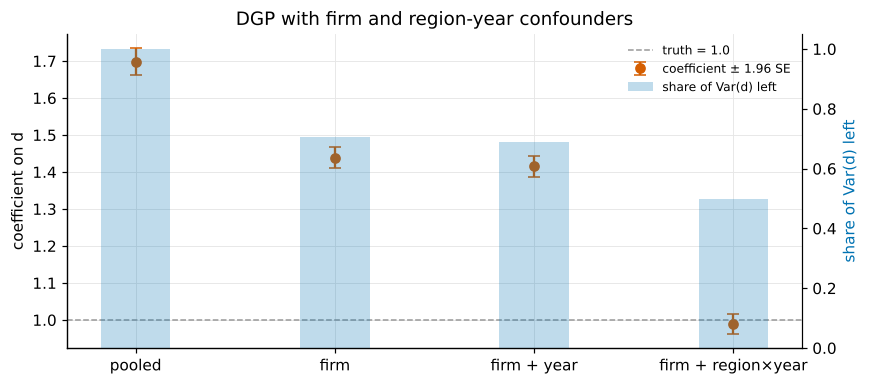

In [3]:
plot_ladder(tab1, title="DGP with firm and region-year confounders")

Two things to read off the figure together: the point estimate and the shaded
bar. Coefficient movement alone does not tell you that a specification is
right (Session 4: Gelbach, Oster); it tells you *where* confounding lived — a
jump when firm FE enter says firm-level, a jump when region×year enters says
region-year-level. Whether what is left is clean is a question about the
design, not about the table.

## 2. The cost side: measurement error and useless fixed effects

Fixed effects remove the variation their cells explain from $d$ — the signal.
They do not remove measurement error in $d$, which is idiosyncratic to the
observation. So every FE set lowers the *reliability ratio*

$$\lambda = \frac{\operatorname{Var}(\ddot d^{\,*})}{\operatorname{Var}(\ddot d^{\,*}) + \operatorname{Var}(\ddot m)},
\qquad \operatorname{plim}\,\hat\delta = \lambda\,\delta,$$

where $\ddot d^{\,*}$ and $\ddot m$ are the true regressor and the noise after
the FE have been projected out (Griliches and Hausman 1986). The FE shrink
the signal with every set; the noise is idiosyncratic, so projecting out
group means barely touches it (for one-way demeaning,
$\operatorname{Var}(\ddot m) = (1 - 1/T)\sigma_m^2$). Below,
credit is observed with noise, $d^{obs}_{it} = d_{it} + m_{it}$,
$m_{it} \sim N(0, 0.7^2)$.

In [4]:
sigma_m = 0.7
df["m"] = rng.normal(0, sigma_m, len(df))
df["d_obs"] = df["d"] + df["m"]

tab2 = ladder(df, "y", "d_obs", SPECS, truth=1.0)
tab2["Var(signal) left"] = [within_share(df, "d", fe) * df["d"].var() for fe in SPECS.values()]
tab2["Var(noise) left"]  = [within_share(df, "m", fe) * df["m"].var() for fe in SPECS.values()]
tab2["predicted attenuation λ"] = tab2["Var(signal) left"] / (tab2["Var(signal) left"] + tab2["Var(noise) left"])
tab2[["coefficient", "SE", "share of Var(d) left", "Var(signal) left", "Var(noise) left", "predicted attenuation λ"]]

,coefficient,SE,share of Var(d) left,Var(signal) left,Var(noise) left,predicted attenuation λ
pooled,1.3181,0.0201,1.0000,1.7044,0.4970,0.7742
firm,1.0431,0.0148,0.7425,1.2036,0.4489,0.7284
firm + year,1.0203,0.0150,0.7297,1.1768,0.4483,0.7241
firm + region×year,0.6493,0.0127,0.5784,0.8507,0.4325,0.6629


The ladder now has two forces: confounding bias falls (upward bias from
$\alpha_i$ and $\gamma_{rt}$ disappears) while attenuation grows (the
remaining signal in $d$ shrinks against a constant noise variance). The last
row is still the best — the confounders are large here — but it sits *below*
one, at roughly $\lambda \cdot 1$. In a design with weak confounding and a
noisy regressor, the fully saturated column can be the most biased one.

The clearest case: a FE set that removes **no confounder at all**. Re-run the
DGP with a region-year component in *credit* that does not enter investment —
think regional credit-supply shocks, which move $d$ but have no direct effect
on $y$. Region×year FE then remove a large part of the signal in $d$ and no
confounding at all: pure cost.

In [5]:
df_nc = make_firm_panel(load_gamma=1.0, gamma_in_y=0.0)  # region-year shocks move d, not y: not a confounder
df_nc["d_obs"] = df_nc["d"] + rng.normal(0, sigma_m, len(df_nc))

tab2b = ladder(df_nc, "y", "d_obs", SPECS, truth=1.0)
tab2b

,coefficient,bias,SE,share of Var(d) left,N
pooled,1.0580,0.0580,0.0186,1.0000,6000
firm,0.7987,-0.2013,0.0096,0.7741,6000
firm + year,0.7942,-0.2058,0.0096,0.7567,6000
firm + region×year,0.6569,-0.3431,0.0130,0.4382,6000


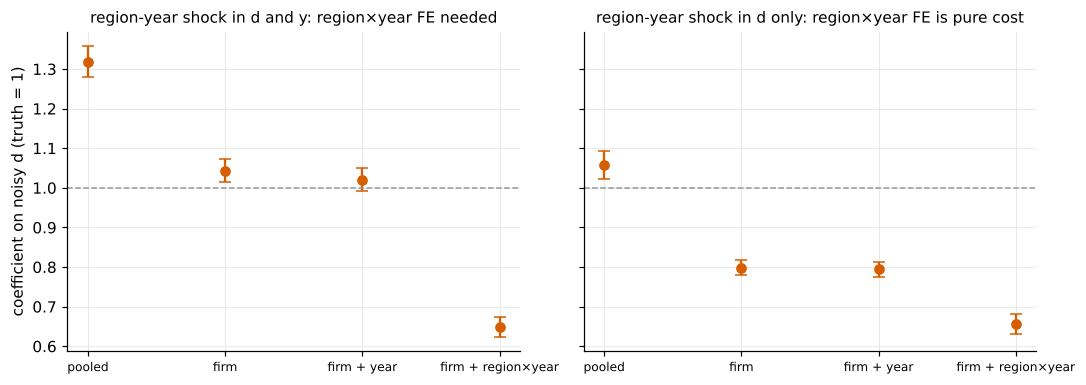

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, tab, ttl in zip(ax, [tab2, tab2b], ["region-year shock in d and y: region×year FE needed", "region-year shock in d only: region×year FE is pure cost"]):
    xs = np.arange(len(tab))
    a.errorbar(xs, tab["coefficient"], yerr=1.96 * tab["SE"], fmt="o", color=VERMILLION, capsize=4, lw=1.5)
    a.axhline(1, color=GREY, ls="--", lw=1); a.set_xticks(xs); a.set_xticklabels(tab.index, fontsize=8); a.set_title(ttl, fontsize=10)
ax[0].set_ylabel("coefficient on noisy d (truth = 1)")
plt.tight_layout(); plt.show()

Right panel: from "firm + year" to "firm + region×year" the coefficient moves
*away* from the truth and the interval widens. Nothing was absorbed except
signal. Breuer and deHaan's rule follows: justify each FE set by the
confounder it removes, not by the reflex that more is safer.

## 3. Fixed effects at the level of the treatment

Suppose credit is not a firm-level variable but a **regional lending
program**: $d_{rt}$ varies across regions and years, not across firms within
a region-year. Then region×year FE absorb the treatment completely —
$\ddot d_{it} = 0$ for every observation — and $\delta$ is not identified. The
rule: fixed effects at the level at which the treatment is assigned, never
finer.

In [7]:
def make_program_panel(R=20, F=30, T=10, delta=1.0, firm_noise=0.0, rng=rng):
    N = R * F
    firm = np.repeat(np.arange(N), T); t = np.tile(np.arange(T), N); region = firm // F
    alpha = rng.normal(0, 1, N); gamma = rng.normal(0, 1, (R, T))
    d_rt = rng.normal(0, 1, (R, T))                                   # program intensity, region-year level
    d = d_rt[region, t] + firm_noise * rng.normal(0, 1, N * T)        # firm_noise > 0: a little firm-level take-up variation
    y = alpha[firm] + gamma[region, t] + delta * d + rng.normal(0, 1, N * T)
    df = pd.DataFrame({"i": firm, "t": t, "r": region, "d": d, "y": y})
    df["rt"] = df["r"].astype(str) + "-" + df["t"].astype(str)
    return df

dfp = make_program_panel()
print("share of Var(d) left after firm + region×year FE:", round(within_share(dfp, "d", ("i", "rt")), 6))
tab3 = ladder(dfp, "y", "d", {"pooled": (), "firm": ("i",), "firm + year": ("i", "t"), "firm + region×year": ("i", "rt")}, truth=1.0)
tab3

share of Var(d) left after firm + region×year FE: 0.0


,coefficient,bias,SE,share of Var(d) left,N
pooled,0.9803,-0.0197,0.0241,1.0000,6000
firm,0.9987,-0.0013,0.0171,0.8396,6000
firm + year,0.9720,-0.0280,0.0169,0.7842,6000
firm + region×year,NaN,NaN,NaN,0.0000,6000


The last row is empty: nothing is left of $d$ after region×year demeaning, so
the helper refuses to estimate (`fixest` and `reghdfe` drop the variable and
say so; a dummy regression in `statsmodels` would print *a* number from a
rank-deficient design). Firm + year FE identify $\delta$ from the region-year variation in the
program, which is what the design offers; here $\gamma_{rt}$ is not correlated
with $d_{rt}$, so that is enough.

The near-miss is more dangerous than the clean failure. Give take-up a *small*
firm-level component — a program at the region-year level with some
firm-specific intensity. Region×year FE no longer absorb everything, the
regression runs, and $\delta$ is identified entirely off the firm-level
residual. If that residual is partly measurement error, attenuation is
severe.

In [8]:
dfp2 = make_program_panel(firm_noise=0.3)
dfp2["d_obs"] = dfp2["d"] + rng.normal(0, 0.3, len(dfp2))            # modest noise relative to the program

tab3b = ladder(dfp2, "y", "d_obs", {"firm + year": ("i", "t"), "firm + region×year": ("i", "rt")}, truth=1.0)
tab3b

,coefficient,bias,SE,share of Var(d) left,N
firm + year,1.0185,0.0185,0.0184,0.8815,6000
firm + region×year,0.4888,-0.5112,0.0327,0.1316,6000


Same regressor, same noise, same truth: with firm + year FE the program
variation carries the identification and the noise is small relative to it;
with region×year FE only the firm-level take-up variation is left, which is
about as large as the noise, and the coefficient is roughly halved. Nothing
in the output flags this — the share-of-variation column is the
only warning, which is why the lecture asks you to report it.

## 4. Singletons

An observation that is alone in its fixed-effects cell is explained perfectly
by its own dummy: its within-cell deviation is zero, it contributes nothing to
$\hat\delta$, and it should not count toward the degrees of freedom either.
With fine cells (region×year in a thin region, firm×year with one loan per
firm) singletons can be a large share of the sample — and they disappear
silently.

Make the panel unbalanced: in a random 40% of region-years only one firm is
observed.

In [9]:
df_u = make_firm_panel()
thin = rng.random((20, 10)) < 0.4                                     # region-years that keep a single firm
keep = np.ones(len(df_u), bool)
for (r, t) in zip(*np.where(thin)):
    idx = df_u.index[(df_u.r == r) & (df_u.t == t)]
    keep[idx[1:]] = False                                             # keep the first firm only
df_u = df_u[keep].copy()

cell_size = df_u.groupby("rt")["i"].transform("size")
df_u["singleton"] = cell_size == 1
dres = demean(df_u, ["d"], ("i", "rt"))["d"]                            # d after firm + region-year FE

print(f"observations: {len(df_u)},  singleton region-years: {int(df_u.singleton.sum())} ({df_u.singleton.mean():.0%})")
print(f"max |within-cell deviation of d| among singletons: {np.abs(dres[df_u.singleton]).max():.2e}")
fit_all  = fe_fit(df_u, "y", "d", ("i", "rt"))
fit_drop = fe_fit(df_u[~df_u.singleton], "y", "d", ("i", "rt"))
pd.DataFrame({"coefficient": [fit_all.params[-1], fit_drop.params[-1]], "SE": [fit_all.bse[-1], fit_drop.bse[-1]],
              "N in regression": [int(fit_all.nobs), int(fit_drop.nobs)]}, index=["singletons in", "singletons dropped"])

observations: 3593,  singleton region-years: 83 (2%)
max |within-cell deviation of d| among singletons: 0.00e+00


,coefficient,SE,N in regression
singletons in,0.9990,0.0183,3593
singletons dropped,0.9990,0.0183,3510


Identical coefficient — the singletons were never in the comparison. The
regression with the singletons "in" reports a larger $N$ than it uses, which
is the mild problem; the real one is interpretive: with firm×year FE in a
loan-level data set, the estimate is about multi-bank firms only, whatever
the $N$ says. That is the next section. (`reghdfe` and `fixest` drop
singletons by default and report how many; `statsmodels` does not.)

## 5. Banking example: Khwaja–Mian vs. industry–location–size–time cells

Does a shock to a bank reduce the credit it extends to its firms? Firm $i$
borrows from bank $b$; in differences,

$$\Delta L_{ib} = \beta\, S_b + \eta_i + u_{ib},$$

with $S_b$ the bank shock (e.g. a deposit outflow) and $\eta_i$ the firm's
credit **demand**. The problem is that demand and exposure are correlated —
weak banks lend to weak firms — so $\beta$ is biased in a pooled regression.

- **Khwaja and Mian (2008):** firm FE. A firm with two banks, one hit and one
  not, holds demand fixed by construction. Single-bank firms are singletons
  and drop out.
- **Degryse et al. (2019):** absorb demand at the industry×location×size
  (×time) cell instead. Every firm stays; demand is held fixed only to the
  extent that it is common within the cell.

Simulation: 3,000 firms, 50 banks, 240 ILS cells (10 industries × 8 locations
× 3 size classes). Demand has a cell component and an idiosyncratic component;
firms sort into a cell's "home bank" with probability 0.6, and the home
bank's shock is correlated with the cell's demand (banks concentrated in
booming cells get inflows). Multi-bank firms are mostly large.

In [10]:
def make_loans(F=3000, B=50, n_ind=10, n_loc=8, n_size=3, beta=1.0, rng=rng):
    ind = rng.integers(0, n_ind, F); loc = rng.integers(0, n_loc, F)
    size = rng.choice(n_size, F, p=[0.6, 0.3, 0.1])                   # most firms are small
    cell = ind * n_loc * n_size + loc * n_size + size
    n_cells = n_ind * n_loc * n_size
    c_cell = rng.normal(0, 1, n_cells)                                # cell-level demand
    home_bank = rng.integers(0, B, n_cells)                           # each cell has a home bank
    # bank shock: correlated with the demand in the cells it serves, plus own noise
    S = np.array([c_cell[home_bank == b].mean() if (home_bank == b).any() else 0 for b in range(B)]) * 0.8 + rng.normal(0, 0.6, B)
    eta = c_cell[cell] + 0.5 * rng.normal(0, 1, F)                    # firm demand = cell part + idiosyncratic part
    p_multi = np.array([0.15, 0.40, 0.65])[size]                      # small / medium / large firms: share with two banks
    n_banks = np.where(rng.random(F) < p_multi, 2, 1)
    rows = []
    for i in range(F):
        b1 = home_bank[cell[i]] if rng.random() < 0.6 else rng.integers(0, B)
        banks = [b1] if n_banks[i] == 1 else [b1, rng.choice([b for b in range(B) if b != b1])]
        for b in banks:
            rows.append((i, b, cell[i], size[i], S[b], eta[i]))
    df = pd.DataFrame(rows, columns=["i", "b", "cell", "size", "S", "eta"])
    df["dL"] = beta * df["S"] + df["eta"] + rng.normal(0, 1, len(df))
    return df

loans = make_loans()
multi = loans.groupby("i")["b"].transform("size") > 1
print(f"loans: {len(loans)}, firms: {loans.i.nunique()}, multi-bank firms: {loans[multi].i.nunique()} "
      f"({loans[multi].i.nunique() / loans.i.nunique():.0%} of firms), of which large: "
      f"{(loans[multi].drop_duplicates('i')['size'] == 2).mean():.0%} (vs. {(loans.drop_duplicates('i')['size'] == 2).mean():.0%} overall)")
print(f"corr(S, eta) across loans: {loans[['S', 'eta']].corr().iloc[0, 1]:.2f}")

loans: 3800, firms: 3000, multi-bank firms: 800 (27% of firms), of which large: 23% (vs. 10% overall)
corr(S, eta) across loans: 0.10


In [11]:
specs = {
    "pooled OLS (all firms)":          (loans, ()),
    "firm FE (Khwaja–Mian)":          (loans[multi], ("i",)),
    "ILS-cell FE (Degryse et al.)":   (loans, ("cell",)),
    "ILS-cell FE, multi-bank only":    (loans[multi], ("cell",)),
}
rows = []
for name, (d_, fe) in specs.items():
    f = fe_fit(d_, "dL", "S", fe, cluster="b")
    rows.append({"coefficient": f.params[-1], "SE": f.bse[-1], "loans": int(f.nobs), "firms": d_.i.nunique(),
                 "share of firms kept": d_.i.nunique() / loans.i.nunique()})
tab5 = pd.DataFrame(rows, index=list(specs))
tab5

,coefficient,SE,loans,firms,share of firms kept
pooled OLS (all firms),1.1554,0.0496,3800,3000,1.0000
firm FE (Khwaja–Mian),0.9521,0.0287,1600,800,0.2667
ILS-cell FE (Degryse et al.),1.0087,0.0192,3800,3000,1.0000
"ILS-cell FE, multi-bank only",0.9494,0.0283,1600,800,0.2667


Read the rows against each other:

- Pooled OLS is biased upward: the bank shock proxies for the demand of the
  cells the bank serves.
- Firm FE recover $\beta = 1$ — on the multi-bank firms only, 27% of the
  firms and disproportionately the large ones. The estimate says nothing
  about the single-bank SME, which is where credit constraints bind.
- ILS-cell FE keep every firm and get close to the truth, because the demand
  that correlates with exposure is the *cell* part. The idiosyncratic part of
  demand is still in the error; here it is independent of the bank, so no
  bias remains. In real data that is the assumption you are making. The
  last row is Degryse et al.'s diagnostic: both estimators on the same
  multi-bank firms. Agreement there supports the cells; it cannot show that
  they absorb demand for the single-bank firms too, whose sorting and demand
  may differ — that part stays an assumption.

That is the trade-off of the lecture in one table: tighter cells absorb
demand better and keep fewer firms.

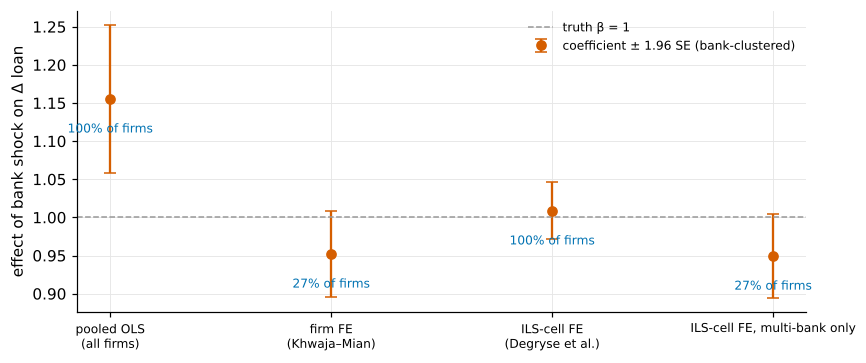

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.4))
xs = np.arange(len(tab5))
ax.errorbar(xs, tab5["coefficient"], yerr=1.96 * tab5["SE"], fmt="o", color=VERMILLION, capsize=4, lw=1.5, label="coefficient ± 1.96 SE (bank-clustered)")
ax.axhline(1, color=GREY, ls="--", lw=1, label="truth β = 1")
for x, (c, s) in enumerate(zip(tab5["coefficient"], tab5["share of firms kept"])):
    ax.annotate(f"{s:.0%} of firms", (x, c), textcoords="offset points", xytext=(0, -22), ha="center", fontsize=8, color=BLUE)
ax.set_xticks(xs); ax.set_xticklabels([s.replace(" (", "\n(") for s in tab5.index], fontsize=8); ax.set_ylabel("effect of bank shock on Δ loan")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

## Summary

- Interacted fixed effects (region×year, bank×year) remove every confounder
  that is common to the cell — and every bit of variation in the regressor
  that the cell explains. Both at once; you cannot have one without the other.
- The saturation ladder shows *where* confounding lived; read coefficient and
  SE together, and report how much variation in $d$ each set leaves.
- Costs that do not show up in the output: attenuation from measurement error
  grows as signal is absorbed; singletons drop out silently; the estimand
  narrows to within-cell comparisons among the units that have them.
- Fixed effects at the level of treatment assignment, never finer; a FE set
  that absorbs the treatment, its mechanism or a post-treatment outcome is a
  bad control (Session 4).
- Khwaja–Mian firm FE vs. ILS cells: absorb demand fully on a selected
  subsample, or approximately on the full sample — compare the two on the
  overlap, and remember the overlap cannot vouch for the single-bank firms.
- Millimet and Bellemare (2025): unit FE remove time-invariant heterogeneity
  only, and not more of it as $T$ grows. Report several panel estimators.

## References

- Breuer, M., and E. deHaan (2024). Using and interpreting fixed effects
  models. *Journal of Accounting Research* 62(4), 1183–1226.
- Degryse, H., O. De Jonghe, S. Jakovljević, K. Mulier, and G. Schepens
  (2019). Identifying credit supply shocks with bank-firm data: Methods and
  applications. *Journal of Financial Intermediation* 40, 100813.
- Griliches, Z., and J. A. Hausman (1986). Errors in variables in panel data.
  *Journal of Econometrics* 31(1), 93–118.
- Khwaja, A. I., and A. Mian (2008). Tracing the impact of bank liquidity
  shocks: Evidence from an emerging market. *American Economic Review* 98(4),
  1413–1442.
- Millimet, D. L., and M. F. Bellemare (2025). On the (mis)use of the fixed
  effects estimator. *Oxford Bulletin of Economics and Statistics*,
  forthcoming (IZA Discussion Paper 16202, 2023).